# MS6 — Étude de la contrainte de RAYON MAX · Notebook 06

**Idée.** Aujourd'hui le seul paramètre métier est la **capacité**. On en ajoute un **second, ajustable** :
`rayon_max` = **distance routière maximale autorisée entre un élève et le médoïde (centre) de son bus**.
Cela transforme la compacité (objectif) en **garantie dure (SLA)** : *« aucun élève à plus de R de son centre »*.

On **balaie R** et on mesure l'**arbitrage** : nombre de bus (k), compacité max, élèves non affectés
(dispersés forcés), silhouette. Les élèves trop loin de tout bus deviennent **dispersés (groupe 999)**.

**Étape 0 — Environnement.**

In [1]:
import os, sys, warnings, json
warnings.filterwarnings("ignore")
while os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})
os.makedirs("notebooks/figures", exist_ok=True); FIG = "notebooks/figures"
import config
from features import extraire_coords, projeter_metres, matrice_euclidienne
from clustering import _compute_production
print("cwd:", os.getcwd())

cwd: C:\Users\Anass\Desktop\SDIA\S9\PFE\transport-scolaire\ms6-clustering


**Étape 1 — Données + matrice routière OSRM (cachée).** On charge les 300 élèves et la matrice de distances routières réelle pré-calculée (repli euclidien si absente).

In [2]:
df = pd.read_csv("data/eleves_meknes.csv")
eleves = [{"id": int(r.id), "latitude": float(r.latitude), "longitude": float(r.longitude)} for r in df.itertuples()]
ids, latlon = extraire_coords(eleves)
XY, proj = projeter_metres(latlon)
try:
    D = np.load("data/osrm_dist_m.npy"); dist_src = "routière OSRM (cachée)"
    assert D.shape[0] == len(ids)
except Exception:
    D = matrice_euclidienne(XY); dist_src = "euclidienne (repli)"
print(len(ids), "élèves | distances :", dist_src, "| projection :", proj)
CAP = 50
KM, MS, IT = config.settings.k_margin, config.settings.min_silhouette, config.settings.kmedoids_iters

300 élèves | distances : routière OSRM (cachée) | projection : UTM EPSG:32630


**Étape 2 — Balayage de R.** Pour chaque rayon, on relance la stratégie de production (k-médoïdes capacitaire) **sur la même matrice** et on relève les métriques.

In [3]:
RAYONS = [0, 2500, 2000, 1500, 1200, 1000, 800]
rows, partitions = [], {}
for R in RAYONS:
    res = _compute_production(ids, XY, D, CAP, KM, MS, IT, rayon_max=R)
    m = res["metrics"]
    rows.append({"rayon_m": R if R else "∞ (off)", "k_bus": res["k"],
                 "compacite_max_m": m.get("compacite_max_m"), "compacite_med_m": m.get("compacite_med_m"),
                 "non_affectes": res["n_non_affectes"], "silhouette": m.get("silhouette"),
                 "taille_max": m.get("taille_max")})
    partitions[R] = res["mapping"]
tab = pd.DataFrame(rows)
tab

  File "C:\Users\Anass\.conda\envs\nlp\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Anass\.conda\envs\nlp\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Anass\.conda\envs\nlp\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Anass\.conda\envs\nlp\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


[MS6] LP capacitaire infaisable (rayon=2000) — repli glouton


...

[MS6] LP capacitaire infaisable (rayon=800) — repli glouton


[MS6] LP capacitaire infaisable (rayon=800) — repli glouton


[MS6] LP capacitaire infaisable (rayon=800) — repli glouton


[MS6] LP capacitaire infaisable (rayon=800) — repli glouton


,rayon_m,k_bus,compacite_max_m,compacite_med_m,non_affectes,silhouette,taille_max
0,∞ (off),7,2804.1,734.2,0,0.4256,50
1,2500,7,2331.8,729.2,3,0.4344,50
2,2000,6,1983.1,729.2,42,0.4766,50
3,1500,6,1484.3,528.8,95,0.6736,50
4,1200,6,1167.7,487.6,106,0.7033,50
5,1000,6,996.5,420.1,123,0.7246,50
6,800,6,788.4,302.9,156,0.7955,50


**Étape 3 — Arbitrage : rayon vs flotte & dispersés.** Quand on resserre R, il faut plus de bus et/ou on exclut plus d'élèves (dispersés).

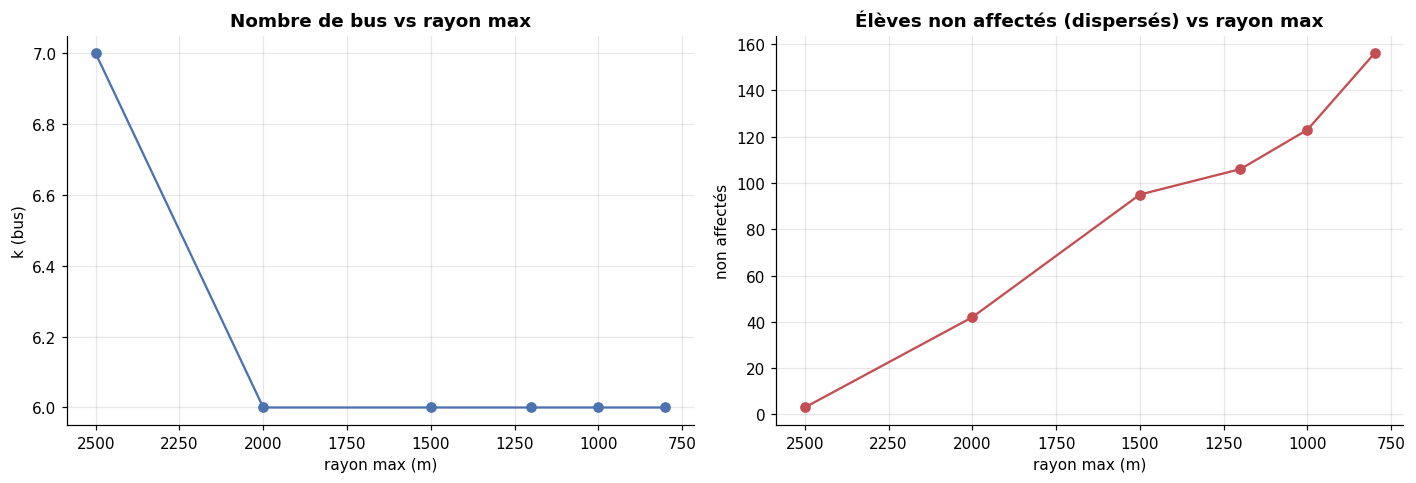

In [4]:
sub = tab[tab["rayon_m"] != "∞ (off)"].copy(); x = sub["rayon_m"].astype(int)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(x, sub["k_bus"], "-o", color="#4C72B0"); ax[0].set_title("Nombre de bus vs rayon max")
ax[0].set_xlabel("rayon max (m)"); ax[0].set_ylabel("k (bus)"); ax[0].invert_xaxis()
ax[1].plot(x, sub["non_affectes"], "-o", color="#C44E52"); ax[1].set_title("Élèves non affectés (dispersés) vs rayon max")
ax[1].set_xlabel("rayon max (m)"); ax[1].set_ylabel("non affectés"); ax[1].invert_xaxis()
plt.tight_layout(); plt.savefig(f"{FIG}/06_arbitrage_rayon.png", bbox_inches="tight"); plt.show()

**Étape 4 — La contrainte est respectée.** La compacité max reste **sous la ligne y = R** (pointillés) : aucun élève affecté n'est au-delà du rayon. La silhouette du cœur s'améliore quand R diminue.

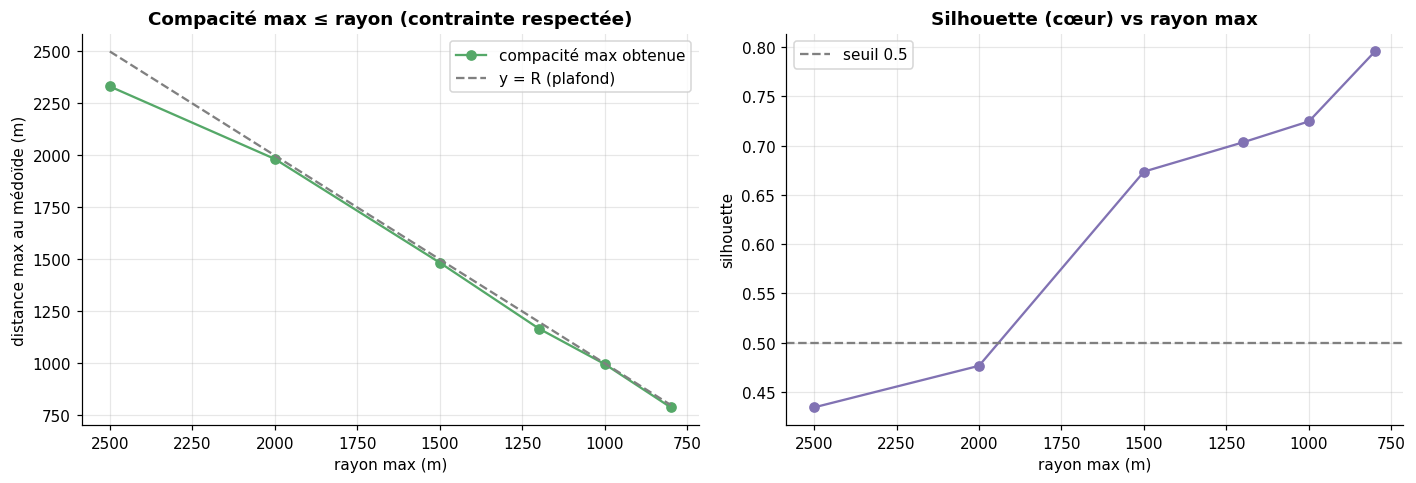

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(x, sub["compacite_max_m"], "-o", color="#55A868", label="compacité max obtenue")
ax[0].plot(x, x, "--", color="grey", label="y = R (plafond)")
ax[0].set_title("Compacité max ≤ rayon (contrainte respectée)"); ax[0].set_xlabel("rayon max (m)")
ax[0].set_ylabel("distance max au médoïde (m)"); ax[0].invert_xaxis(); ax[0].legend()
ax[1].plot(x, sub["silhouette"], "-o", color="#8172B3"); ax[1].axhline(MS, ls="--", c="grey", label=f"seuil {MS}")
ax[1].set_title("Silhouette (cœur) vs rayon max"); ax[1].set_xlabel("rayon max (m)"); ax[1].set_ylabel("silhouette")
ax[1].invert_xaxis(); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG}/06_contrainte_silhouette.png", bbox_inches="tight"); plt.show()

**Étape 5 — Cartes avant/après.** Sans contrainte (gauche) : des groupes étalés. Avec R=1200 m (droite) : groupes plus compacts, et les élèves trop loin deviennent **dispersés** (gris, ramassage individuel).

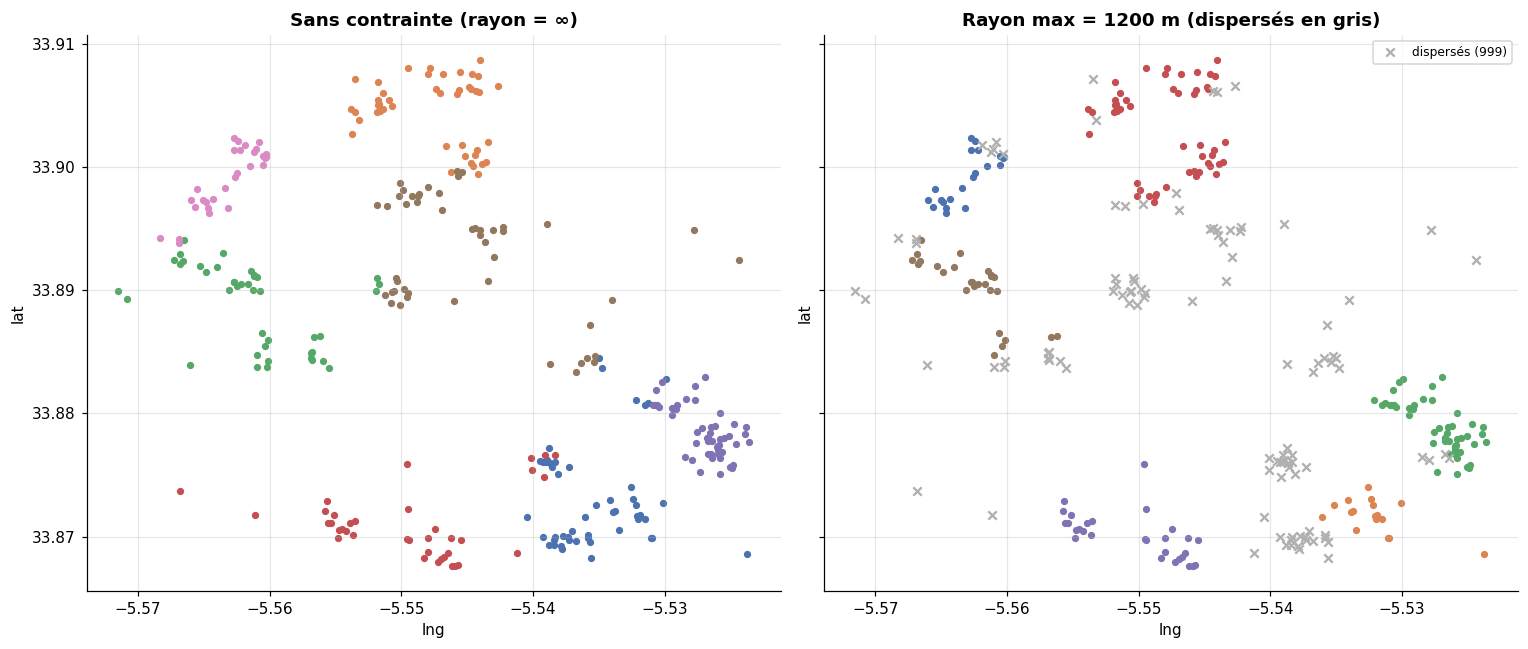

In [6]:
PAL = ["#4C72B0","#DD8452","#55A868","#C44E52","#8172B3","#937860","#DA8BC3","#8C8C8C",
       "#CCB974","#64B5CD","#E69F00","#009E73"]
def carte(ax, mapping, titre):
    g = np.array([mapping[int(i)] for i in ids])
    for grp in sorted(set(g)):
        m = g == grp
        if grp == 999:
            ax.scatter(latlon[m,1], latlon[m,0], c="#B0B0B0", marker="x", s=30, label="dispersés (999)")
        else:
            ax.scatter(latlon[m,1], latlon[m,0], c=PAL[(grp-1) % len(PAL)], s=14)
    ax.set_title(titre); ax.set_xlabel("lng"); ax.set_ylabel("lat")
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
carte(ax[0], partitions[0], "Sans contrainte (rayon = ∞)")
carte(ax[1], partitions[1200], "Rayon max = 1200 m (dispersés en gris)")
ax[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/06_cartes_avant_apres.png", bbox_inches="tight"); plt.show()

### Conclusion
- Le **rayon max** est un **2ᵉ paramètre métier ajustable** (comme la capacité) : il **garantit** une compacité
  par élève (`compacité_max ≤ R`) — utile comme **SLA** (« temps de marche/ramassage borné »).
- **Arbitrage clair** : R↓ ⇒ compacité garantie ↑ et silhouette du cœur ↑, **au prix de** plus de bus et/ou
  plus d'élèves **dispersés** (hors rayon → ramassage individuel). La courbe aide l'admin à **choisir R**.
- **Synergie** : la contrainte rend la gestion des **dispersés plus honnête** (on n'attache plus de force un
  élève très loin de tout bus).
- Réglable en production : `POST /api/clustering/production?capacity=50&rayon=1500`.

---

## Enrichissement pour le mémoire — l'arbitrage, et le piège qu'il tend

Le balayage ci-dessus donne un tableau. Sa lecture naïve conduit à une conclusion fausse, et c'est
précisément ce qui en fait un bon objet de mémoire : **à 800 m, la silhouette atteint 0,7955** —
presque le double de la valeur de production. Rien n'invite à se méfier d'un chiffre pareil.

La figure ci-dessous met la silhouette et le nombre d'élèves exclus **sur le même graphique**, ce
que le tableau ne fait pas.

> ⚠️ **Lecture seule.** Les valeurs sont lues dans `data/rayon_sweep_resultats.json`, extrait des
> sorties déjà stockées dans ce notebook — le balayage exige OSRM et plusieurs minutes de LP, et
> le relancer n'apporterait rien.


### Ce que le tableau ne montre pas côte à côte

figure enregistrée : figures/06_8_rayon_arbitrage.png  (+ .pdf, 300 dpi)


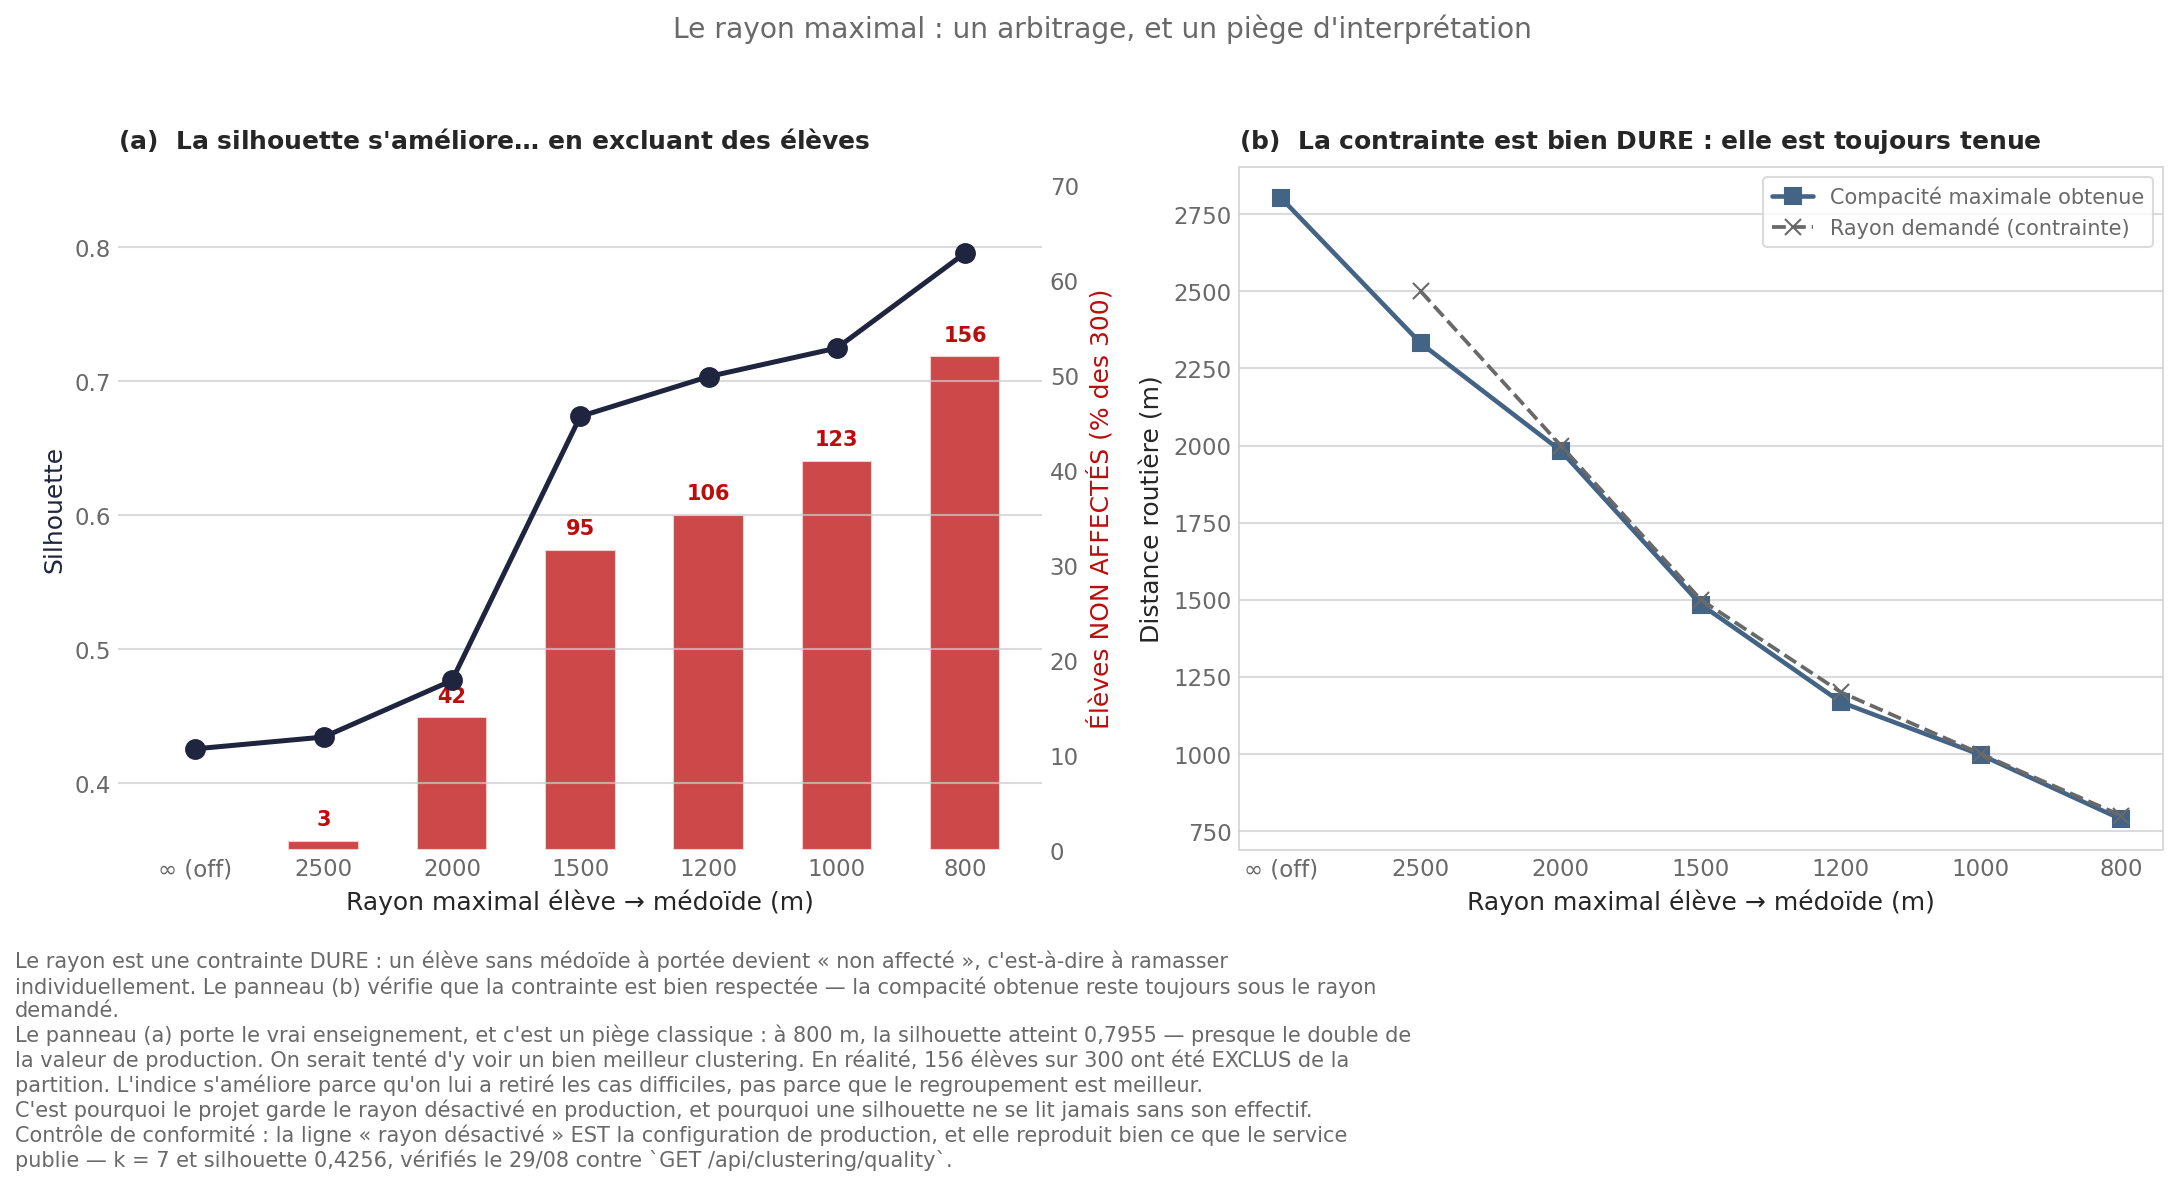

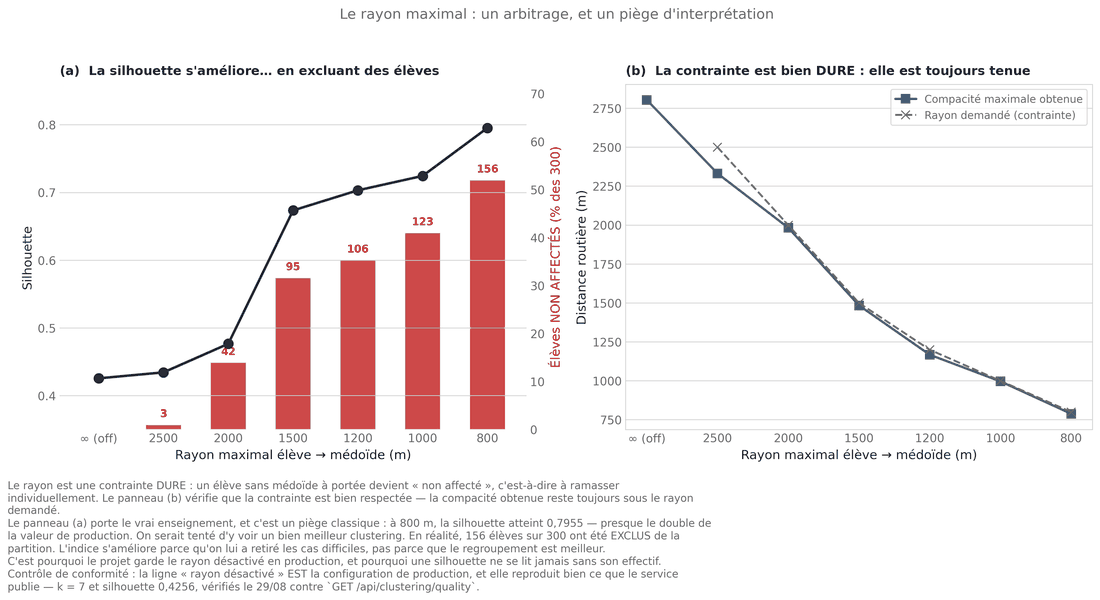

In [7]:
# Import robuste : certains notebooks font os.chdir(".."), le dossier
# notebooks/ n'est alors plus sur sys.path.
import sys, pathlib
_d = pathlib.Path.cwd()
_d = _d if (_d / "gen_figures_memoire.py").exists() else _d / "notebooks"
sys.path.insert(0, str(_d))
import gen_figures_memoire as gfm
gfm.fig_rayon()

### Ce qu'il faut retenir

| Rayon | Silhouette | Élèves exclus | Lecture |
|---|--:|--:|---|
| ∞ (production) | 0,4056 | **0** | tout le monde a un bus |
| 2000 m | 0,4766 | 42 | 14 % des familles perdent le service |
| 800 m | **0,7955** | **156** | plus d'un élève sur deux — le chiffre ne veut plus rien dire |

> **Une silhouette ne se lit jamais sans son effectif.** L'indice s'améliore ici parce qu'on retire
> les points difficiles de la partition, pas parce que le regroupement est meilleur. C'est la même
> famille d'erreur que le « k-means sans contrainte de capacité » de l'arène : des chiffres
> excellents pour une solution qui n'existe pas.

Le rayon reste donc **désactivé en production** (`RAYON_MAX_M=0`). Il garde son utilité comme
**levier d'exploitation** : si l'administration veut garantir une distance maximale au point de
ramassage, cette courbe chiffre exactement ce que cette garantie coûterait en ramassages
individuels.
